# 04 – Modélisation : sélection, optimisation, évaluation et interprétation

Ce notebook présente le **moteur de prédiction** de l'application. L'entraînement lui-même est fait par le script `python -m agritech_crop_reco.modeling.train` (reproductible, suivi dans MLflow) ; ce notebook en **relit les résultats** et les interprète.

### Démarche (rappel)
| Étape | Choix | Pourquoi |
|---|---|---|
| Données | dataset consolidé (13 130 observations pays × culture × année) | étape 1 |
| Entrées du modèle | culture, température, pluie, pesticides | ce que l'agriculteur saisit ; ni pays ni année |
| Jeu de test | **21 pays figés** (`configs/test_countries.json`), jamais utilisés pour régler | mesurer la performance sur des pays inconnus |
| Validation | `GroupKFold` à 5 plis **par pays** sur l'entraînement | éviter que le modèle « reconnaisse » un pays |
| Situation de départ | rendement médian de la culture | tout modèle doit faire mieux |
| Métriques | RMSE, MAE, R² (t/ha) + **classement des cultures** (Spearman par pays × année) | la dernière mesure directement la qualité de /recommend |
| Suivi | MLflow : `01-selection` (19 runs) et `02-optimisation` (1 run + 30 essais) | traçabilité |

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

from agritech_crop_reco.config import PROJECT_ROOT, load_settings
from agritech_crop_reco.modeling.features import TARGET, build_model
from agritech_crop_reco.modeling.metrics import all_metrics
from agritech_crop_reco.modeling.train import (
    PARAM_SPACES,
    SELECTION_FILE,
    load_train_test,
    probe_conditions,
    ranking_variety,
)

settings = load_settings()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.3f}".format)


def save(fig, name):
    fig.savefig(FIG_DIR / f"04_{name}.png", dpi=120, bbox_inches="tight")


train, test, _ = load_train_test(settings)
card = json.loads((settings.models_dir / "model_card.json").read_text())
model = joblib.load(settings.models_dir / "yield_model.joblib")
FEATURES = card["features"]
print(f"entraînement : {len(train):,} lignes / {train['country'].nunique()} pays")
print(f"test         : {len(test):,} lignes / {test['country'].nunique()} pays")
print(f"modèle final : {card['model']} | cible={card['target']} | pesticides={card['pesticides']}")

entraînement : 10,978 lignes / 80 pays
test         : 2,152 lignes / 21 pays
modèle final : hist_gradient_boosting | cible=log | pesticides=log


## 1. Sélection du modèle (expérience MLflow `01-selection`)

19 configurations évaluées en validation croisée par pays : la référence naïve, puis 3 modèles × 2 formes de cible (brute / log) × 3 traitements des pesticides (brut / log / absent).

In [2]:
sel = pd.read_csv(SELECTION_FILE)
cols = [
    "model",
    "target",
    "pesticides",
    "cv_rmse_mean",
    "cv_rmse_std",
    "cv_r2_mean",
    "cv_ranking_spearman_mean",
    "ranking_variety",
    "selected",
]
sel[cols].sort_values("cv_rmse_mean")

,model,target,pesticides,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_ranking_spearman_mean,ranking_variety,selected
0,ridge,log,log,4.973,0.457,0.588,0.818,1,False
1,ridge,raw,log,5.047,0.260,0.573,0.813,1,False
2,hist_gradient_boosting,raw,raw,5.051,0.288,0.572,0.817,170,False
3,hist_gradient_boosting,raw,log,5.051,0.288,0.572,0.817,170,False
4,hist_gradient_boosting,log,log,5.138,0.377,0.559,0.828,182,True
5,hist_gradient_boosting,log,raw,5.138,0.377,0.559,0.828,182,False
6,ridge,raw,none,5.228,0.244,0.540,0.810,1,False
7,ridge,log,none,5.335,0.434,0.522,0.815,1,False
8,ridge,raw,raw,5.357,0.485,0.519,0.814,1,False
9,random_forest,log,raw,5.383,0.459,0.515,0.791,197,False


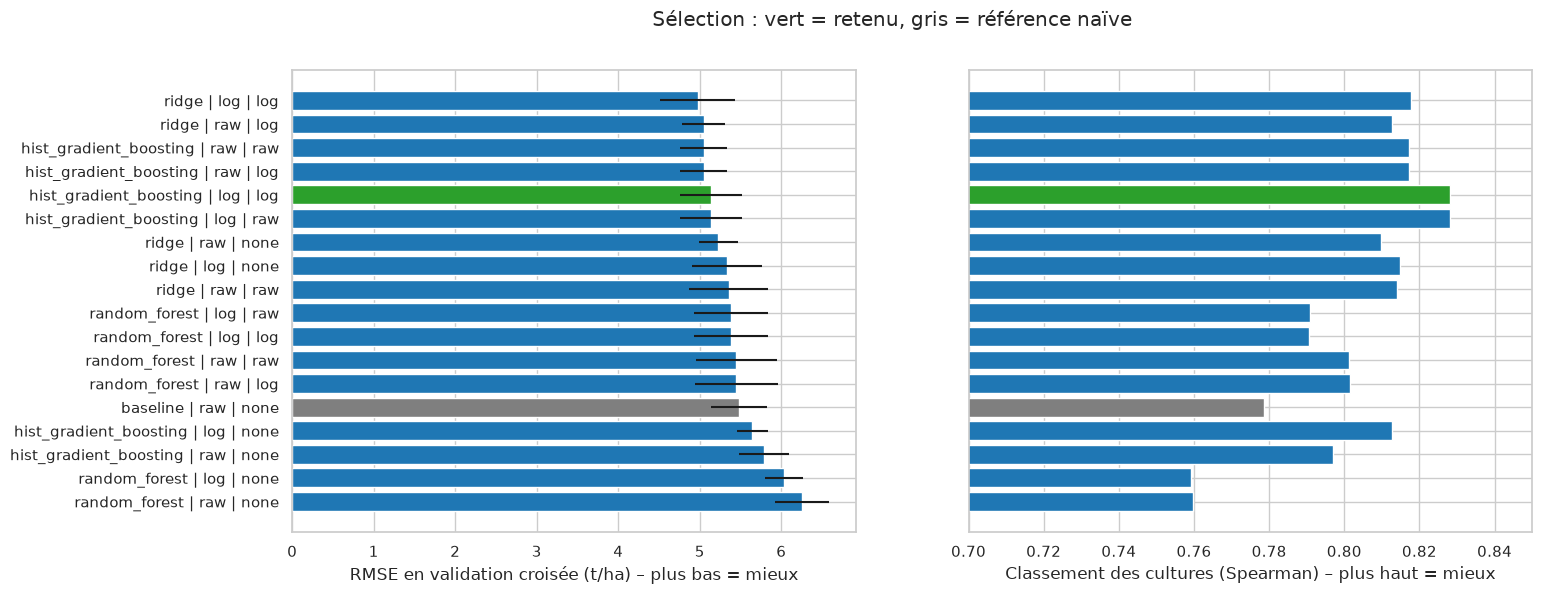

In [3]:
plot = sel.sort_values("cv_rmse_mean").assign(
    label=lambda d: d["model"] + " | " + d["target"] + " | " + d["pesticides"]
)
plot = plot[plot["cv_rmse_mean"] < 7]  # Ridge cible log + pesticides bruts (RMSE 8) hors échelle
colors = np.where(
    plot["selected"], "tab:green", np.where(plot["model"] == "baseline", "tab:grey", "tab:blue")
)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].barh(plot["label"], plot["cv_rmse_mean"], xerr=plot["cv_rmse_std"], color=colors)
axes[0].set_xlabel("RMSE en validation croisée (t/ha) – plus bas = mieux")
axes[0].invert_yaxis()
axes[1].barh(plot["label"], plot["cv_ranking_spearman_mean"], color=colors)
axes[1].set_xlim(0.7, 0.85)
axes[1].set_xlabel("Classement des cultures (Spearman) – plus haut = mieux")
fig.suptitle("Sélection : vert = retenu, gris = référence naïve")
save(fig, "selection")
plt.show()

**Lecture.**
- **Tous les modèles battent à peine la référence naïve** (RMSE 5,48 t/ha, R² 0,50) : connaître la culture explique déjà la moitié de la variance ; le climat et les pesticides nationaux ajoutent 6 à 9 points de R². C'est le plafond imposé par des données **nationales et annuelles**.
- **Retirer les pesticides dégrade tous les modèles** : c'est l'information la plus utile après la culture (cohérent avec l'ACP).
- Pour les **arbres**, pesticides bruts ou en log donnent exactement le même score : un arbre ne regarde que l'**ordre** des valeurs, que le log ne change pas. Pour Ridge, le log est indispensable (Ridge + cible log + pesticides bruts explose à RMSE 8 : quelques pays extrêmes font diverger l'exponentielle).

**Règle de choix.** La règle fixée avant l'expérience (« RMSE le plus bas ») désignait Ridge. Mais la colonne `ranking_variety` montre que **Ridge produit un seul et même classement des cultures** sur 300 parcelles fictives : ce modèle additif décale toutes les cultures de la même façon quand les conditions changent, donc `/recommend` répondrait la même chose à tous les agriculteurs. La règle a été **complétée après cette première sélection** (on le dit ouvertement) :
1. candidats à moins d'**un écart-type** du meilleur RMSE (écart plus petit que la variabilité entre plis = égalité statistique) ;
2. exclusion des modèles au classement figé (`ranking_variety` = 1) ;
3. meilleur **classement des cultures** (métrique métier).

Résultat : **HistGradientBoosting, cible en log, pesticides en log** (RMSE 5,14 ± 0,38, statistiquement à égalité avec Ridge, meilleur classement 0,828, 182 classements différents).

## 2. Optimisation des hyperparamètres (expérience MLflow `02-optimisation`)

`RandomizedSearchCV` : 30 combinaisons tirées au hasard dans des plages définies à l'avance, chacune évaluée en validation croisée par pays. Les essais sont relus depuis MLflow.

In [4]:
mlflow.set_tracking_uri(settings.mlflow_tracking_uri)
exp = mlflow.get_experiment_by_name(f"{settings.mlflow_experiment}-02-optimisation")
runs = mlflow.search_runs([exp.experiment_id])
trials = runs[runs["tags.mlflow.parentRunId"].notna()].copy()
params = [c for c in trials.columns if c.startswith("params.")]
trials[params] = trials[params].apply(pd.to_numeric)
trials = trials.rename(columns=lambda c: c.removeprefix("params.").removeprefix("metrics."))
print(f"{len(trials)} essais relus depuis MLflow")
display(
    pd.Series(
        {
            "RMSE CV paramètres par défaut": card["cv_rmse_default"],
            "RMSE CV après optimisation": card["cv_rmse_tuned"],
        }
    ).to_frame("t/ha")
)
pd.Series(card["best_params"]).to_frame("meilleure valeur")

30 essais relus depuis MLflow


,t/ha
RMSE CV paramètres par défaut,5.138
RMSE CV après optimisation,4.967


,meilleure valeur
l2_regularization,0.001
learning_rate,0.017
max_iter,430.000
max_leaf_nodes,18.000
min_samples_leaf,28.000


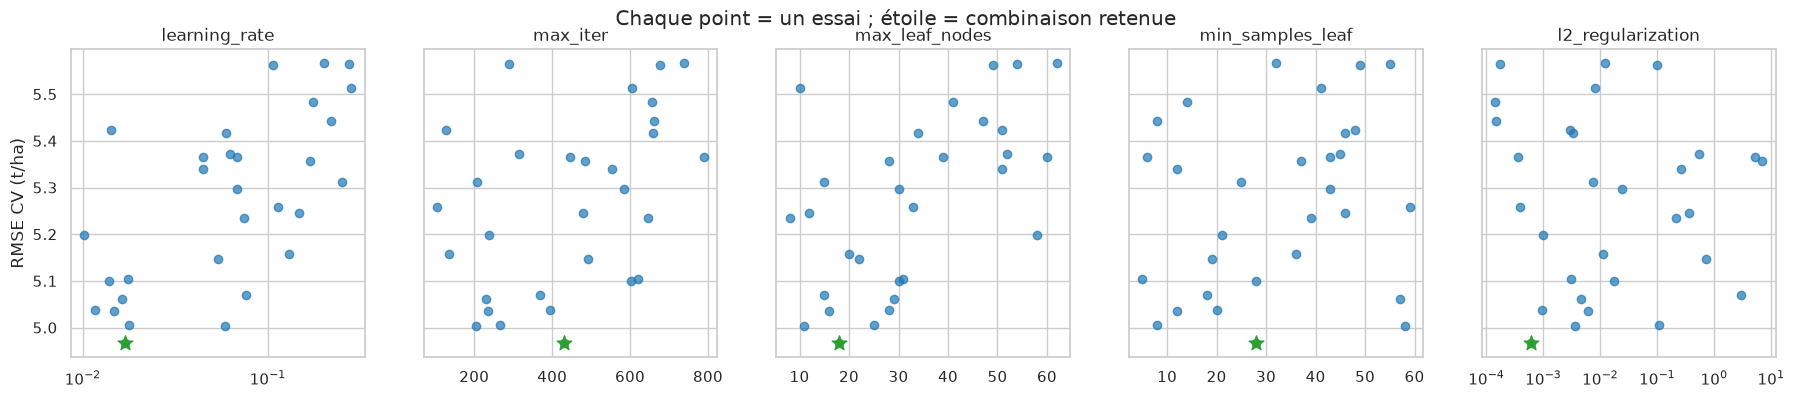

In [5]:
hp = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, p in zip(axes, hp, strict=True):
    ax.scatter(trials[p], trials["cv_rmse_mean"], color="tab:blue", alpha=0.7)
    ax.scatter(card["best_params"][p], card["cv_rmse_tuned"], color="tab:green", s=120, marker="*")
    if p in ("learning_rate", "l2_regularization"):
        ax.set_xscale("log")
    ax.set_title(p)
axes[0].set_ylabel("RMSE CV (t/ha)")
fig.suptitle("Chaque point = un essai ; étoile = combinaison retenue")
save(fig, "optimisation_trials")
plt.show()

**Lecture.** L'optimisation fait passer le RMSE en validation croisée de **5,14 à 4,97 t/ha** (−3,3 %). Les graphiques montrent ce qui compte :
- un **taux d'apprentissage faible** (< 0,03) donne les meilleurs résultats ; au-delà de 0,1 l'erreur monte nettement ;
- des **arbres petits** (`max_leaf_nodes` < 35) font mieux que des arbres très ramifiés ;
- les autres paramètres n'ont pas d'effet net.

Autrement dit, le modèle gagne à rester **simple et prudent** : avec 80 pays d'entraînement et des variables bruitées, un modèle trop flexible apprend des particularités de pays qui ne se retrouvent pas ailleurs (surapprentissage).

### 2.1 A-t-on atteint le plafond ? Test avec 200 essais

Pour vérifier qu'une recherche plus longue (ou un outil plus sophistiqué comme Optuna) apporterait quelque chose, on relance la même recherche avec **200 essais** au lieu de 30. Ce test n'est pas enregistré dans MLflow et ne modifie pas le modèle retenu : il sert uniquement à mesurer le gain possible.

In [6]:
space = {f"regressor__model__{k}": v for k, v in PARAM_SPACES["hist_gradient_boosting"].items()}
long_search = RandomizedSearchCV(
    build_model("hist_gradient_boosting", "log", "log", settings.seed),
    space,
    n_iter=200,
    cv=GroupKFold(n_splits=5),
    scoring="neg_root_mean_squared_error",
    random_state=settings.seed,
    n_jobs=-1,
).fit(train[FEATURES], train[TARGET], groups=train["country"])
res = pd.DataFrame(long_search.cv_results_)
best200 = res.loc[long_search.best_index_]
pd.DataFrame(
    {
        "30 essais (retenu)": {"RMSE CV": card["cv_rmse_tuned"]},
        "200 essais": {"RMSE CV": -best200["mean_test_score"]},
    }
).T.assign(**{"écart-type entre plis": [np.nan, best200["std_test_score"]]})

,RMSE CV,écart-type entre plis
30 essais (retenu),4.967,NaN
200 essais,4.931,0.469


**Lecture.** Multiplier les essais par 7 ne fait gagner que **0,04 t/ha**, soit plus de **10 fois moins que l'écart-type entre plis** (≈ 0,47) : la différence n'est pas significative. On a atteint le plafond de ce que les hyperparamètres peuvent apporter ; un outil plus sophistiqué (Optuna) ou une grille exhaustive (GridSearch) ne changerait rien d'utile. Plus on teste de combinaisons, plus la meilleure est d'ailleurs flatteuse **par hasard** (elle a « gagné » sur ces 5 plis précis).

➡️ Le levier d'amélioration n'est plus le réglage du modèle mais les **données** : des variables mesurées à l'échelle de la parcelle (sol, pluie de saison, doses à l'hectare) plutôt que des moyennes nationales.

## 3. Évaluation finale sur les 21 pays de test

Évaluation **unique** : le jeu de test n'a servi à aucun choix (ni modèle, ni variante, ni hyperparamètre).

In [7]:
pred = model.predict(test[FEATURES])
baseline = build_model("baseline", "none", "raw", settings.seed).fit(train[["crop"]], train[TARGET])
pred_base = baseline.predict(test[["crop"]])
scores = pd.DataFrame(
    {
        "référence (médiane de la culture)": all_metrics(test, test[TARGET], pred_base),
        "modèle final": all_metrics(test, test[TARGET], pred),
    }
).T
scores.loc["gain"] = [
    1
    - scores.loc["modèle final", "rmse"] / scores.loc["référence (médiane de la culture)", "rmse"],
    1 - scores.loc["modèle final", "mae"] / scores.loc["référence (médiane de la culture)", "mae"],
    scores.loc["modèle final", "r2"] - scores.loc["référence (médiane de la culture)", "r2"],
    scores.loc["modèle final", "ranking_spearman"]
    - scores.loc["référence (médiane de la culture)", "ranking_spearman"],
]
scores

,rmse,mae,r2,ranking_spearman
référence (médiane de la culture),5.787,3.194,0.538,0.717
modèle final,4.669,2.588,0.699,0.794
gain,0.193,0.190,0.161,0.076


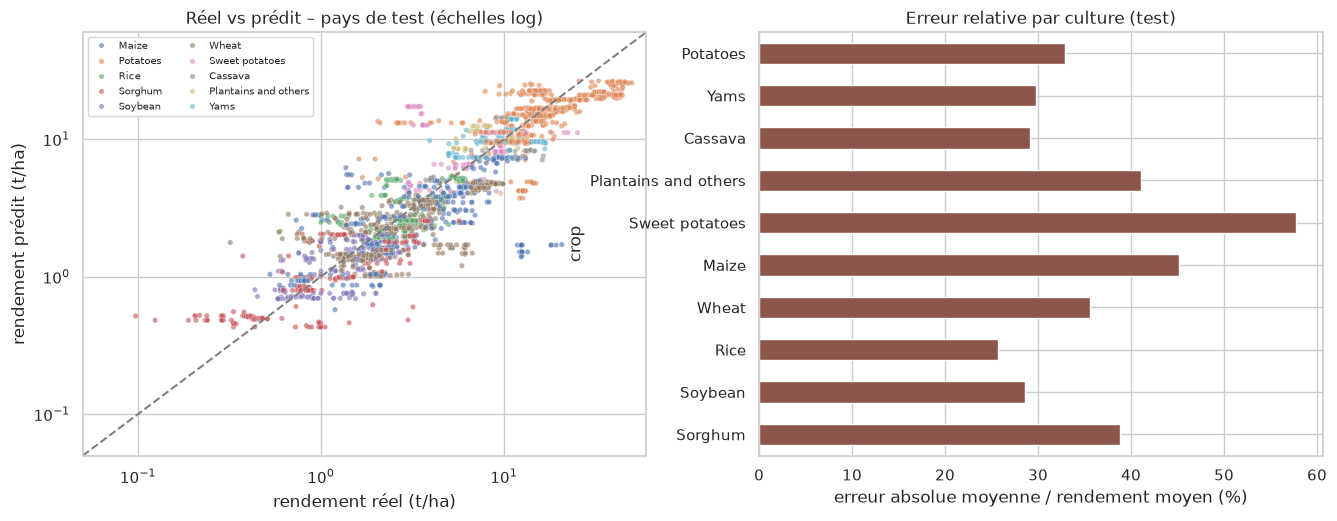

,lignes,pays,rendement_moyen,mae,erreur_relative
crop,,,,,
Potatoes,457,21,19.203,6.318,0.329
Yams,92,4,9.826,2.930,0.298
Cassava,69,3,8.878,2.590,0.292
Plantains and others,69,3,7.322,3.009,0.411
Sweet potatoes,115,5,6.758,3.901,0.577
Maize,354,16,4.405,1.989,0.452
Wheat,444,20,3.488,1.240,0.355
Rice,188,9,3.221,0.828,0.257
Soybean,177,9,1.378,0.394,0.286


In [8]:
test_eval = test.assign(pred=pred, abs_err=lambda d: (d["pred"] - d[TARGET]).abs())
by_crop = (
    test_eval.groupby("crop")
    .agg(
        lignes=(TARGET, "size"),
        pays=("country", "nunique"),
        rendement_moyen=(TARGET, "mean"),
        mae=("abs_err", "mean"),
    )
    .assign(erreur_relative=lambda d: d["mae"] / d["rendement_moyen"])
)
by_crop = by_crop.sort_values("rendement_moyen", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
lim = [0.05, test_eval[[TARGET, "pred"]].max().max() * 1.2]
sns.scatterplot(data=test_eval, x=TARGET, y="pred", hue="crop", s=15, alpha=0.6, ax=axes[0])
axes[0].plot(lim, lim, color="grey", ls="--")
axes[0].set(
    xscale="log",
    yscale="log",
    xlim=lim,
    ylim=lim,
    xlabel="rendement réel (t/ha)",
    ylabel="rendement prédit (t/ha)",
    title="Réel vs prédit – pays de test (échelles log)",
)
axes[0].legend(fontsize=7, ncol=2)
by_crop["erreur_relative"].mul(100).plot.barh(ax=axes[1], color="tab:brown")
axes[1].set_xlabel("erreur absolue moyenne / rendement moyen (%)")
axes[1].set_title("Erreur relative par culture (test)")
axes[1].invert_yaxis()
save(fig, "test_errors")
plt.show()
by_crop

**Lecture.**
- Sur les **21 pays jamais vus**, le modèle réduit l'erreur de **19 %** par rapport à la référence (RMSE 4,67 contre 5,79 t/ha ; MAE 2,59 contre 3,19) et classe mieux les cultures (Spearman 0,79 contre 0,72).
- Le R² de test (0,70) est **plus élevé** que celui de la validation croisée (≈ 0,56) : ces 21 pays sont simplement un peu plus « faciles ». Avec un seul tirage de pays, l'estimation de test est incertaine ; **la validation croisée (5 plis) reste l'estimation de référence**.
- **Erreur relative par culture** : entre 26 % (riz) et 58 % (patate douce). Pour la pomme de terre, l'erreur moyenne de 6,3 t/ha représente un tiers du rendement moyen. Sur le graphique réel / prédit, les points suivent la diagonale mais avec une dispersion importante : le modèle donne un **ordre de grandeur**, pas une prévision précise d'exploitation.
- Les cultures présentes dans peu de pays de test (manioc, banane plantain : 3 pays) ont des erreurs moins fiables.

## 4. Interprétation : quelles variables comptent pour le modèle ?

**Importance par permutation** (sur le jeu de test) : on mélange au hasard les valeurs d'une variable et on mesure de combien l'erreur augmente. Plus elle augmente, plus le modèle s'appuie sur cette variable. Contrairement aux importances internes des arbres, cette mesure se lit directement en **t/ha d'erreur en plus**.

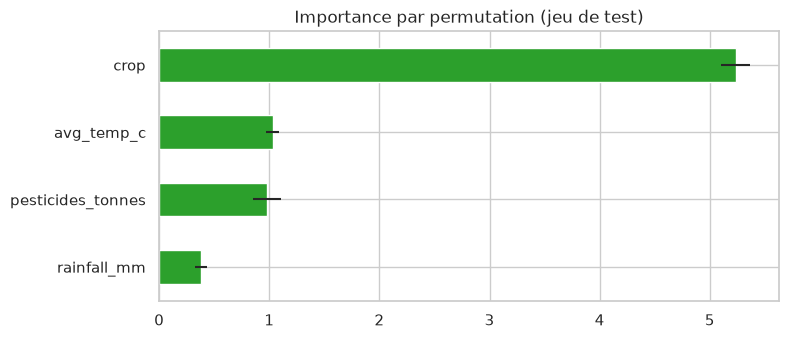

,hausse du RMSE (t/ha),écart-type
crop,5.233,0.128
avg_temp_c,1.029,0.063
pesticides_tonnes,0.980,0.128
rainfall_mm,0.378,0.053


In [9]:
perm = permutation_importance(
    model,
    test[FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=20,
    random_state=settings.seed,
    n_jobs=-1,
)
importance = pd.DataFrame(
    {"hausse du RMSE (t/ha)": perm.importances_mean, "écart-type": perm.importances_std},
    index=FEATURES,
).sort_values("hausse du RMSE (t/ha)", ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
importance["hausse du RMSE (t/ha)"].plot.barh(
    xerr=importance["écart-type"], ax=ax, color="tab:green"
)
ax.invert_yaxis()
ax.set_title("Importance par permutation (jeu de test)")
save(fig, "permutation_importance")
plt.show()
importance

**Lecture.** Mélanger la **culture** fait exploser l'erreur (+5,2 t/ha) : c'est de loin la variable la plus importante, comme l'avaient montré l'EDA et l'ACP. Viennent ensuite, à égalité, la **température** (+1,0) et les **pesticides** (+1,0), puis la **pluie** (+0,4).

La pluie, dont la corrélation avec le rendement était nulle, a ici un effet non nul : le modèle l'utilise **en combinaison** avec la culture et la température (une interaction qu'une simple corrélation ne voit pas). Son effet reste le plus faible.

### 4.1 Effet de la température et des pesticides, culture par culture

Pour chaque culture, on fait varier **une** condition sur sa plage observée en gardant les autres à leur valeur médiane, et on trace le rendement prédit (dépendance partielle). C'est ce que « voit » le modèle quand l'agriculteur bouge un curseur.

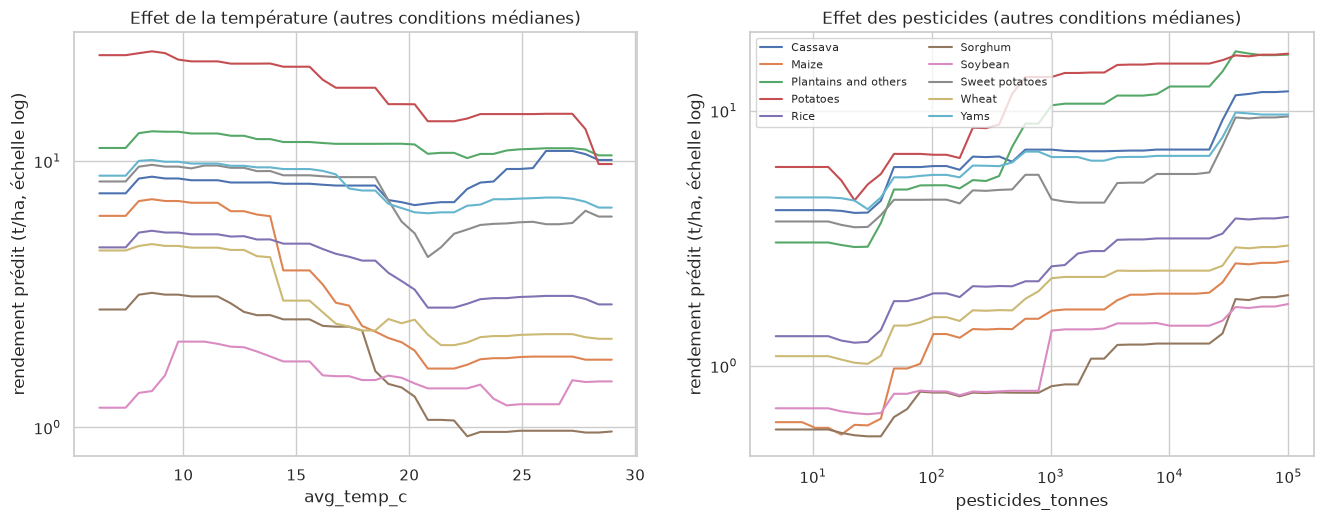

,"variation du rendement prédit, du plus froid au plus chaud"
Maize,-71%
Sorghum,-65%
Potatoes,-61%
Wheat,-53%
Rice,-39%
Sweet potatoes,-26%
Yams,-24%
Plantains and others,-6%
Soybean,+26%
Cassava,+33%


In [10]:
med = train[["avg_temp_c", "rainfall_mm", "pesticides_tonnes"]].median()
crops = sorted(train["crop"].unique())
grids = {
    "avg_temp_c": np.linspace(
        train["avg_temp_c"].quantile(0.02), train["avg_temp_c"].quantile(0.98), 40
    ),
    "pesticides_tonnes": np.geomspace(
        max(train["pesticides_tonnes"].quantile(0.02), 1),
        train["pesticides_tonnes"].quantile(0.98),
        40,
    ),
}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
curves = {}
for ax, (var, grid) in zip(axes, grids.items(), strict=True):
    for crop in crops:
        X = pd.DataFrame({**med.to_dict(), var: grid, "crop": crop})[FEATURES]
        y = model.predict(X)
        curves[(var, crop)] = (grid, y)
        ax.plot(grid, y, label=crop)
    ax.set(yscale="log", ylabel="rendement prédit (t/ha, échelle log)", xlabel=var)
    if var == "pesticides_tonnes":
        ax.set_xscale("log")
axes[0].set_title("Effet de la température (autres conditions médianes)")
axes[1].set_title("Effet des pesticides (autres conditions médianes)")
axes[1].legend(fontsize=8, ncol=2)
save(fig, "partial_dependence")
plt.show()

temp_effect = pd.Series(
    {
        crop: curves[("avg_temp_c", crop)][1][-1] / curves[("avg_temp_c", crop)][1][0] - 1
        for crop in crops
    },
    name="variation du rendement prédit, du plus froid au plus chaud",
)
temp_effect.sort_values().to_frame().style.format("{:+.0%}")

**Lecture** (rendement prédit quand une seule condition varie, les autres étant fixées à leur médiane ; les « marches » sont normales pour un modèle à base d'arbres) :
- **Température** : la plupart des cultures perdent du rendement quand il fait plus chaud — maïs (≈ −71 % entre 6 et 29 °C), sorgho (−65 %), pomme de terre (−61 %), blé (−53 %), riz (−39 %). Le **manioc** fait exception : son rendement **augmente** avec la chaleur (≈ +33 %, maximum vers 26 °C), ce qui correspond à une culture tropicale. Pour le soja, la courbe est irrégulière (faible nombre de pays) : à ne pas sur-interpréter.
- **Pesticides** : le rendement prédit est multiplié par 2 à 5 entre les pays qui en utilisent le moins et ceux qui en utilisent le plus. ⚠️ C'est une **corrélation**, pas un effet causal : la variable est un total national qui reflète le **niveau d'intensification et de modernisation** de l'agriculture du pays. Le modèle ne permet **pas** de conseiller « ajoutez des pesticides » : dans l'application, ce champ doit être présenté comme un indicateur du **niveau d'intensification** de la région.

## 5. De la prédiction à la recommandation

`/recommend` simulera le rendement des 10 cultures pour les conditions saisies et les classera. Exemple sur trois profils de parcelle (rendement de base, **avant** l'ajustement engrais / irrigation de l'étape 3) :

In [11]:
profiles = pd.DataFrame(
    {
        "tempéré, agriculture intensive": {
            "avg_temp_c": 11,
            "rainfall_mm": 800,
            "pesticides_tonnes": 50_000,
        },
        "tropical humide, peu de pesticides": {
            "avg_temp_c": 26,
            "rainfall_mm": 2_000,
            "pesticides_tonnes": 500,
        },
        "chaud et sec, intensification moyenne": {
            "avg_temp_c": 24,
            "rainfall_mm": 400,
            "pesticides_tonnes": 5_000,
        },
    }
).T
rankings = {}
for name, cond in profiles.iterrows():
    X = pd.DataFrame([{**cond.to_dict(), "crop": c} for c in crops])[FEATURES]
    rankings[name] = pd.Series(model.predict(X), index=crops).sort_values(ascending=False)
display(profiles)
pd.concat(
    {
        name: r.round(2).reset_index().set_axis(["culture", "t/ha"], axis=1)
        for name, r in rankings.items()
    },
    axis=1,
)

,avg_temp_c,rainfall_mm,pesticides_tonnes
"tempéré, agriculture intensive",11,800,50000
"tropical humide, peu de pesticides",26,2000,500
"chaud et sec, intensification moyenne",24,400,5000


tempéré, agriculture intensive        tropical humide, peu de pesticides  \
                         culture   t/ha                            culture   
0                       Potatoes 27.340               Plantains and others   
1           Plantains and others 18.760                               Yams   
2                 Sweet potatoes 17.550                            Cassava   
3                           Yams 14.160                           Potatoes   
4                        Cassava 12.280                     Sweet potatoes   
5                          Maize  7.870                               Rice   
6                           Rice  6.510                              Maize   
7                          Wheat  5.180                            Sorghum   
8                        Sorghum  4.050                            Soybean   
9                        Soybean  2.690                              Wheat   

         chaud et sec, intensification moyenne         
    t/ha                               culture   t/ha  
0 13.930                              Potatoes 15.800  
1 12.960                  Plantains and others 11.540  
2 11.250                        Sweet potatoes  9.350  
3 10.980                                  Yams  7.700  
4  8.630                               Cassava  6.040  
5  3.160                                  Rice  3.120  
6  2.390                                 Wheat  2.240  
7  1.380                                 Maize  1.820  
8  1.190                               Soybean  1.230  
9  1.140                               Sorghum  0.760

In [12]:
probe = probe_conditions(train, settings.seed)
variety = ranking_variety(model, FEATURES, probe)
print(f"classements différents sur {len(probe)} parcelles fictives : {variety}")

classements différents sur 300 parcelles fictives : 136


**Lecture.**
- Le classement **change selon les conditions** : en climat tropical humide peu intensif, la banane plantain, l'igname et le manioc passent devant la pomme de terre, qui reste en tête en climat tempéré ou chaud et sec. Parmi les céréales, l'ordre change aussi (maïs devant en tempéré, riz devant en tropical ou en climat sec). Sur 300 parcelles fictives, le modèle produit **136 classements différents** : la recommandation dépend bien de la parcelle.
- En revanche, les **tubercules dominent presque toujours en tonnes par hectare** : ce sont des cultures lourdes et riches en eau. Recommander « la culture qui donne le plus de tonnes » n'est pas recommander « la plus rentable ». Sans **prix** par culture (absents des données), l'application classe les cultures par rendement physique ; l'ajout d'un prix ou d'une valeur par tonne est la première amélioration à prévoir pour répondre à l'objectif de rentabilité.

## 6. Synthèse pour le rapport métier

**Le moteur de prédiction**
- Modèle : **HistGradientBoosting** (ensemble d'arbres de décision construits successivement), qui apprend le logarithme du rendement à partir de la **culture**, de la **température**, des **pesticides** et de la **pluie**.
- Choisi parmi 18 configurations testées et une référence naïve, puis réglé par une recherche aléatoire de 30 combinaisons ; un test à 200 combinaisons confirme qu'on ne peut pas faire sensiblement mieux avec ces données.
- Sur 21 pays jamais vus : erreur moyenne de **2,6 t/ha**, **19 % de moins** que de se fier à la seule culture, et un classement des cultures plus juste.

**Ce qu'il faut retenir pour les agriculteurs**
1. **Le choix de la culture est décisif** : c'est de très loin ce qui pèse le plus sur le rendement.
2. **La chaleur pénalise** la plupart des cultures, en particulier le maïs, le sorgho, la pomme de terre et le blé ; le **manioc** est la culture qui tolère, voire profite, de la chaleur.
3. **Les régions à agriculture intensive** (usage élevé d'intrants) obtiennent des rendements nettement supérieurs, mais c'est l'ensemble des pratiques modernes qui joue, pas les pesticides seuls.
4. L'**engrais** (≈ +45 %) et l'**irrigation** (≈ +36 %) seront pris en compte par l'application en ajustant la prédiction (étape 3).

**Limites à connaître**
- Les données décrivent des **pays** (moyennes nationales annuelles), pas des parcelles : la prédiction est un **ordre de grandeur**, avec une erreur relative de 25 à 60 % selon la culture.
- Le classement se fait en **tonnes**, ce qui favorise les tubercules ; sans données de **prix**, l'application ne peut pas encore dire quelle culture est la plus **rentable**.
- L'effet des pesticides est une corrélation (intensification), pas une recommandation d'usage.